# Phase 3: Features + classification (kritikaa, patient 22)

Regions to classify = the blobs kritikaa's **own Phase 2 method (geodesic active contour)** returns, i.e. exactly what the app hands to the classifier.
All three search areas from Phase 2 are used (ground-truth liver, predicted liver, convex hull of the predicted liver); a blob found more than once is kept once.
- **tumour** blob = at least 50% of its pixels inside the ground-truth tumour
- **healthy** blob = no tumour pixels at all (false alarm of the segmentation); blobs in between are skipped

Features: shape + GLCM (0/45/90/135 degrees) + first-order HU + **border sharpness** (kritikaa's own set). Classifier: **random forest** (100 decision trees that vote).

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "kritikaa"
SLICES = f"../data/slices/{NAME}"
ENH = "../phase1/outputs_kritikaa/enhanced"
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
os.makedirs(OUT, exist_ok=True)
slice_ids = sorted(os.path.basename(f).replace("_enh.png", "") for f in glob.glob(f"{ENH}/*_enh.png"))
print(len(slice_ids), "slices")

def load(sid):
    return (np.load(f"{SLICES}/{sid}_ct.npy"), cv2.imread(f"{ENH}/{sid}_enh.png", 0),
            cv2.imread(f"{SLICES}/{sid}_liver.png", 0) > 0, cv2.imread(f"{SLICES}/{sid}_tumour.png", 0) > 0)

from scipy.stats import skew, kurtosis
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops

ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]

def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area, perim = r.area, max(r.perimeter, 1e-6)
    return {"area": area, "perimeter_area_ratio": perim / area,
            "circularity": 4 * np.pi * area / perim ** 2,      # 1 = perfect circle
            "compactness": perim ** 2 / area,
            "eccentricity": r.eccentricity,                      # 0 = circle, 1 = line
            "solidity": r.solidity}                              # area / convex hull area

def glcm_features(enh, mask, levels=32, per_angle=False):
    """GLCM texture inside the region only (pixels outside the region are ignored)."""
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch, m = enh[r0:r1, c0:c1].astype(int), mask[r0:r1, c0:c1]
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)   # 1..levels inside, 0 outside
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)[1:, 1:, :, :].astype(float)
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)
    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])
        feats.update({f"glcm_{prop}_{a}": v for a, v in zip(ANGLE_NAMES, vals)} if per_angle
                     else {f"glcm_{prop}": vals.mean()})
    ent = [-(P[:, :, 0, k][P[:, :, 0, k] > 0] * np.log2(P[:, :, 0, k][P[:, :, 0, k] > 0])).sum() for k in range(4)]
    feats.update({f"glcm_entropy_{a}": v for a, v in zip(ANGLE_NAMES, ent)} if per_angle
                 else {"glcm_entropy": np.mean(ent)})
    return feats

def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    return {"mean_HU": hu.mean(), "variance_HU": hu.var(),
            "skewness": skew(hu) if hu.std() > 0 else 0.0,
            "kurtosis": kurtosis(hu) if hu.std() > 0 else 0.0}

def glcm_angle_table(enh, mask):
    t = pd.Series(glcm_features(enh, mask, per_angle=True))
    return pd.DataFrame({a: t[[k for k in t.index if k.endswith("_" + a)]].values for a in ANGLE_NAMES},
                        index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3)

12 slices


In [2]:
MIN_AREA = 10
GAC_GT_LIVER = "../phase2/outputs_kritikaa/gac"                    # Phase 2 final method, ground-truth liver as search area
GAC_PRED_LIVER = "../phase2/outputs_kritikaa/predicted_liver"      # same method, predicted liver as search area
GAC_HULL_LIVER = "../phase2/outputs_kritikaa/hull_liver"          # same method, convex hull of the predicted liver

def candidate_masks(sid):
    return [cv2.imread(f"{GAC_GT_LIVER}/{sid}_tumour_pred.png", 0) > 0,
            cv2.imread(f"{GAC_PRED_LIVER}/{sid}_gac_tumour_pred.png", 0) > 0,
            cv2.imread(f"{GAC_HULL_LIVER}/{sid}_gac_tumour_pred.png", 0) > 0]

rois, skipped = [], 0
for sid in slice_ids:
    ct, enh, liver, tumour = load(sid)
    seen = []
    for cand in candidate_masks(sid):
        for r in regionprops(label(cand)):
            m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
            if r.area < MIN_AREA or any((m == s).all() for s in seen):     # too small, or already found with the other liver
                continue
            seen.append(m)
            inside = tumour[m].mean()                                      # share of the blob that is real tumour
            if inside >= 0.5:
                rois.append((sid, m, 1))
            elif inside == 0:
                rois.append((sid, m, 0))
            else:
                skipped += 1
labels = np.array([y for _, _, y in rois])
print(len(rois), "regions:", (labels == 1).sum(), "tumour,", (labels == 0).sum(), "healthy |", skipped, "mixed blobs skipped")

sid, m, _ = max((r for r in rois if r[2] == 1), key=lambda r: r[1].sum())
print(f"\nGLCM at 4 angles, largest tumour region ({sid}):")
print(glcm_angle_table(load(sid)[1], m))

glcm_example = glcm_angle_table(load(sid)[1], m)
glcm_example.to_csv(f"{FIGS}/{NAME}_glcm_table.csv")

58 regions: 24 tumour, 34 healthy | 10 mixed blobs skipped

GLCM at 4 angles, largest tumour region (p22_s130):
                 0     45     90    135
energy       0.283  0.261  0.253  0.240
contrast     0.610  1.008  0.926  1.285
homogeneity  0.767  0.719  0.708  0.653
correlation  0.940  0.898  0.905  0.868
entropy      4.368  4.664  4.656  4.821


In [3]:
SE_PLUS_5 = np.zeros((5, 5), np.uint8); SE_PLUS_5[2, :] = 1; SE_PLUS_5[:, 2] = 1; SE_PLUS_5[1:4, 1:4] = 1
SE_PLUS_7 = np.zeros((7, 7), np.uint8); SE_PLUS_7[3, :] = 1; SE_PLUS_7[:, 3] = 1; SE_PLUS_7[2:5, 2:5] = 1

def border_features(ct, enh, mask):
    """kritikaa's own feature set: how sharp the region's border is. A tumour usually has a clear step in HU at
    its edge; a vessel cut at an angle or a partial-volume smear has a weaker, more uneven edge."""
    m8 = mask.astype(np.uint8)
    ring = cv2.dilate(m8, SE_PLUS_7, iterations=2).astype(bool) & ~mask      # a band just outside the region
    edge = mask & ~(cv2.erode(m8, SE_PLUS_5) > 0)                             # the region's own outline pixels
    grad = np.hypot(cv2.Sobel(enh, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(enh, cv2.CV_64F, 0, 1, ksize=3))
    g = grad[edge] if edge.any() else grad[mask]
    return {"border_HU_step": ct[ring].mean() - ct[mask].mean(),             # how much brighter the surroundings are
            "border_gradient_mean": g.mean(),                                  # average edge strength
            "border_gradient_cv": g.std() / (g.mean() + 1e-9)}                 # 0 = equally sharp all round

cache, rows = {}, []
for sid, m, y in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enh, _, _ = cache[sid]
    rows.append({"slice": sid, "label": y, **shape_features(m), **glcm_features(enh, m), **first_order_features(ct, m),
                 **border_features(ct, enh, m)})
features = pd.DataFrame(rows)
features.to_csv(f"{OUT}/phase3_features.csv", index=False)
print(features.groupby("label").mean(numeric_only=True).T.round(3).rename(columns={0: "healthy", 1: "tumour"}))

label                  healthy   tumour
area                   147.176  803.000
perimeter_area_ratio     0.402    0.173
circularity              0.796    0.823
compactness             17.273   15.616
eccentricity             0.832    0.603
solidity                 0.915    0.936
glcm_energy              0.284    0.308
glcm_contrast            8.587    1.044
glcm_homogeneity         0.522    0.706
glcm_correlation         0.602    0.782
glcm_entropy             4.355    4.131
mean_HU                  5.832   47.039
variance_HU           8256.104  350.185
skewness                -0.128    0.198
kurtosis                 0.062    0.161
border_HU_step          44.960   25.404
border_gradient_mean   177.233   92.815
border_gradient_cv       0.601    0.487


In [4]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- groups: every region from the same slice stays on the same side of the split ----
# Neighbouring slices show the same tumour, so a random split of regions would put near-copies in train AND test.
# Consecutive slices are joined into blocks of 3 (or 2) only if that still leaves >= 5 training groups for 5-fold CV.
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position = slice_no.map({s: i for i, s in enumerate(sorted(slice_no.unique()))}).values   # 0, 1, 2, ... along the scan
def grouped_split(groups):
    """70/30 split by group. Groups differ in size, so try 50 seeds and keep the one whose test part is closest
    to 30% of the REGIONS (only sizes are looked at, never the scores). Needs >= 5 train groups + both classes in test."""
    best_split, best_gap = None, 1.0
    for seed in range(50):
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(X, y, groups))
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and abs(len(te) / len(y) - 0.3) < best_gap:
            best_split, best_gap = (tr, te), abs(len(te) / len(y) - 0.3)
    return best_split

for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

from sklearn.ensemble import RandomForestClassifier
# random forest: 100 decision trees, each trained on a random sample of regions/features; they vote
# 5-fold grouped cross-validation on the 70% TRAIN part only picks the max depth; the 30% test part stays untouched
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42)),
                      {"randomforestclassifier__max_depth": [3, 5, 8, None]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["randomforestclassifier__max_depth"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned max depth = {best}  (tried [3, 5, 8, None])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")
cv_summary = {"tuned max depth": best, "group block (slices)": BLOCK,
              "CV accuracy mean": cv["test_accuracy"].mean(), "CV accuracy std": cv["test_accuracy"].std(),
              "CV F1 mean": cv["test_f1"].mean(), "CV F1 std": cv["test_f1"].std()}

block = 1 slice(s) per group | train: 8 groups, 41 regions | test: 4 groups, 17 regions (29% of all regions)

C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


tuned max depth = 3  (tried [3, 5, 8, None])
5-fold grouped CV on train: accuracy 0.968 +/- 0.039  folds: [1.    0.933 0.909 1.    1.   ]
                            F1       0.760 +/- 0.383  folds: [1.    0.909 0.889 0.    1.   ]


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Test set: 17 regions (10 tumour, 7 healthy)
  accuracy               0.824
  sensitivity (recall)   0.700
  specificity            1.000
  F1                     0.824


95% bootstrap CI (test groups resampled):
  accuracy               [0.640, 1.000]
  sensitivity (recall)   [0.357, 1.000]
  specificity            [1.000, 1.000]
  F1                     [0.526, 1.000]


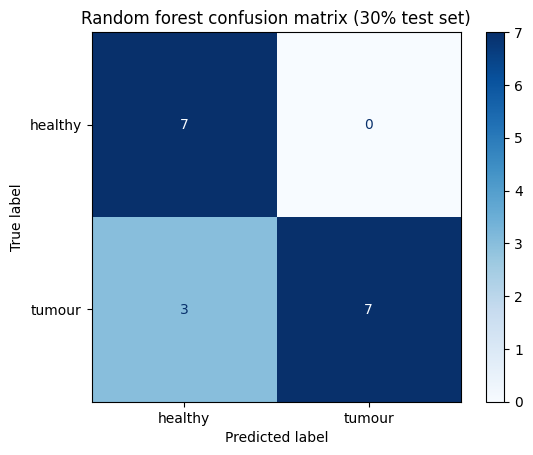

In [5]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "sensitivity (recall)": tp / (tp + fn) if tp + fn else 0,   # tumours correctly found
           "specificity": tn / (tn + fp) if tn + fp else 0,            # healthy correctly cleared
           "F1": f1_score(y_test, y_pred, zero_division=0)}
print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k, v in metrics.items():
    print(f"  {k:22s} {v:.3f}")
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    return [accuracy_score(t, p), tp / (tp + fn) if tp + fn else np.nan, tn / (tn + fp) if tn + fp else np.nan,
            f1_score(t, p, zero_division=0)]
boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
boot = []
for _ in range(2000):
    pick = np.concatenate([np.where(test_groups == g)[0] for g in boot_rng.choice(np.unique(test_groups), len(np.unique(test_groups)))])
    boot.append(scores(y_test[pick], y_pred[pick]))
lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
ci = {}
print("95% bootstrap CI (test groups resampled):")
for k, a, b in zip(metrics, lo, hi):
    ci[f"{k} CI low"], ci[f"{k} CI high"] = a, b
    print(f"  {k:22s} [{a:.3f}, {b:.3f}]")
pd.DataFrame([{**metrics, **cv_summary, **ci}]).to_csv(f"{OUT}/phase3_metrics.csv", index=False)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                       display_labels=["healthy", "tumour"]).plot(cmap="Blues")
plt.title("Random forest confusion matrix (30% test set)")
plt.savefig(f"{FIGS}/{NAME}_p3_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

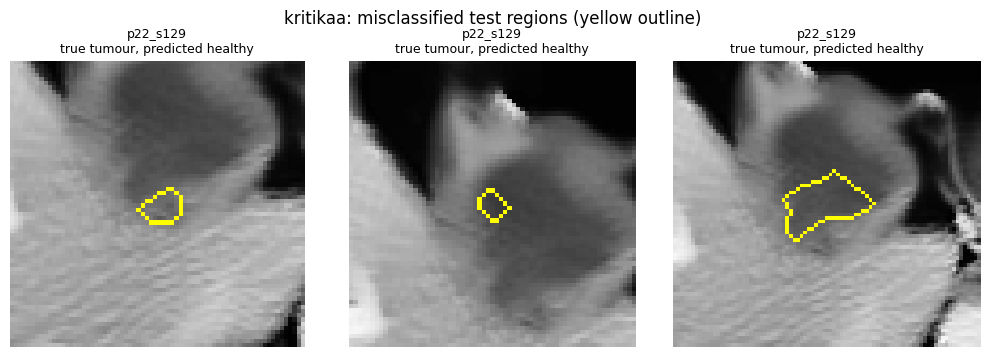

# Phase 3 failed cases: kritikaa

Test set: 17 regions, **3 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |
|---|---|---|---|---|---|
| p22_s129 | tumour | healthy | 68 | 64 | glcm_correlation 0.268 (z -9.0), perimeter_area_ratio 0.426 (z +6.7), glcm_contrast 2.04 (z +4.9) |
| p22_s129 | tumour | healthy | 39 | 28 | perimeter_area_ratio 0.538 (z +9.4), variance_HU 202 (z -4.6), circularity 1.11 (z +4.1) |
| p22_s129 | tumour | healthy | 274 | 44 | glcm_homogeneity 0.779 (z +2.8), perimeter_area_ratio 0.26 (z +2.7), solidity 0.87 (z -2.7) |


In [6]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = f"../report/failed_cases/{NAME}"
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}
lines = [f"# Phase 3 failed cases: {NAME}", "",
         f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.", "",
         "| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |", "|---|---|---|---|---|---|"]
feat_cols = list(features.columns[2:])
train_feats = features.iloc[idx_train]
for i in wrong:
    sid, m, true = rois[i]
    row = features.iloc[i]
    # measured reason: the 3 features where this region is most unlike the TRAINING regions of its true class (|z-score|)
    own_class = train_feats[train_feats.label == true][feat_cols]
    z = ((row[feat_cols] - own_class.mean()) / (own_class.std() + 1e-9)).astype(float)
    top = z.abs().sort_values(ascending=False).index[:3]
    why = ", ".join(f"{f} {row[f]:.3g} (z {z[f]:+.1f})" for f in top)
    lines.append(f"| {sid} | {names[true]} | {names[1 - true]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        sid, m, true = rois[i]
        rgb = cv2.cvtColor(load(sid)[1], cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        ys, xs = np.where(m)
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        a.imshow(rgb[y0:y1, x0:x1]); a.axis("off")
        a.set_title(f"{sid}\ntrue {names[true]}, predicted {names[1 - true]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_p3_misclassified.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")
open(f"{FAILED}/{NAME}_phase3_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

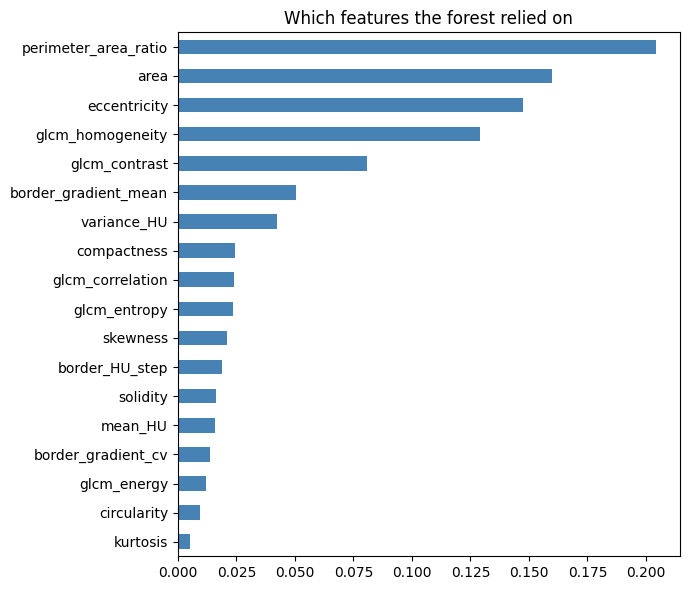

saved model to outputs_kritikaa/rf_model.joblib


In [7]:
model.fit(X, y)
importance = pd.Series(model[-1].feature_importances_, index=features.columns[2:]).sort_values()
importance.plot.barh(figsize=(7, 6), color="steelblue"); plt.title("Which features the forest relied on")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p3_feature_importance.png", dpi=120); plt.show()
joblib.dump({"model": model, "feature_names": list(features.columns[2:])}, f"{OUT}/rf_model.joblib")
print("saved model to", f"{OUT}/rf_model.joblib")

**Feature analysis.** 1) Box plots of every feature, healthy vs tumour. 2) Mann-Whitney U test per feature (does the feature differ between the classes? no normal distribution needed). 3) Ablation: the same tuned classifier trained on one feature group at a time, scored with the same grouped split (grouped 5-fold CV on the 70% + the untouched 30%).

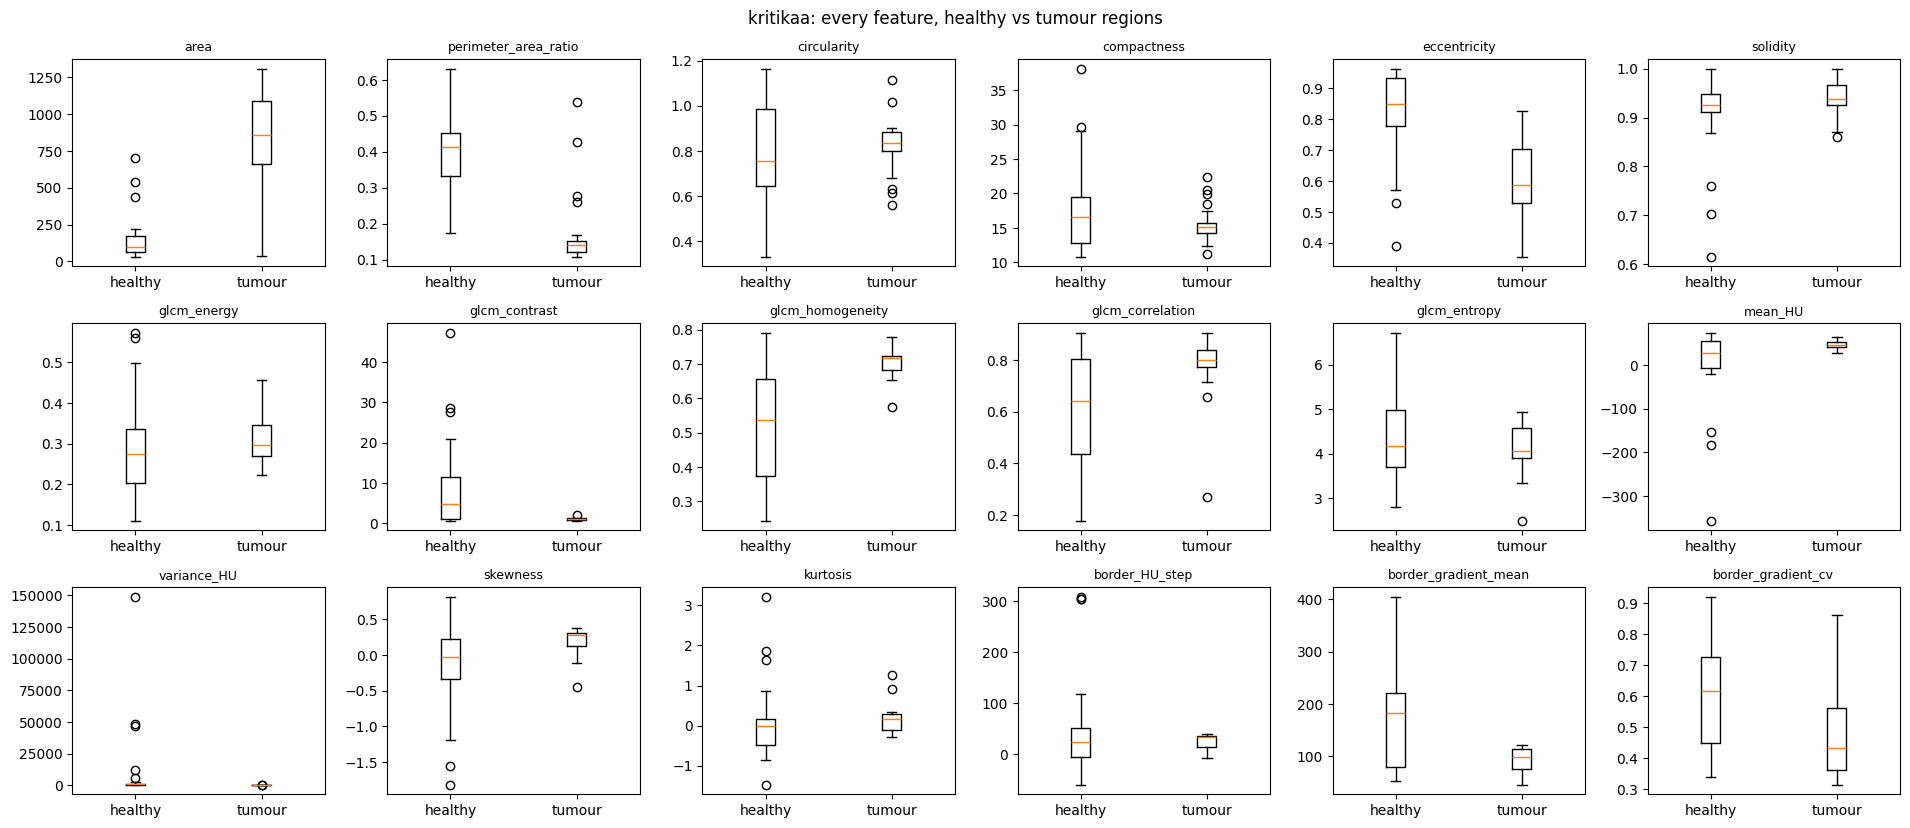

Mann-Whitney U, healthy vs tumour (smallest p first):
             feature  median healthy  median tumour  p-value  significant (p < 0.05)
perimeter_area_ratio          0.4146         0.1418   0.0000                    True
                area         96.5000       855.0000   0.0000                    True
        eccentricity          0.8510         0.5865   0.0000                    True
    glcm_homogeneity          0.5382         0.7171   0.0000                    True
       glcm_contrast          4.8136         0.9486   0.0000                    True
    glcm_correlation          0.6398         0.7999   0.0011                    True
         variance_HU        725.3289       352.1822   0.0024                    True
border_gradient_mean        182.4320        99.3820   0.0025                    True
  border_gradient_cv          0.6181         0.4328   0.0086                    True
            skewness         -0.0331         0.2765   0.0098                    True
           

C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Ablation (same tuned classifier, same grouped split):
                                        features  n  CV F1 mean  CV F1 std  test accuracy  test F1
                                    all features 18       0.760      0.383          0.824    0.824
                                      shape only  6       0.760      0.383          0.824    0.824
                                       GLCM only  5       0.492      0.405          0.765    0.778
                                first-order only  4       0.627      0.364          0.765    0.800
                           border sharpness only  3       0.559      0.298          0.706    0.737
all except area / perimeter-area ratio (no size) 16       0.716      0.363          0.765    0.778

Region area (pixels) per class:
          min     max  median
label                        
healthy  31.0   701.0    96.5
tumour   39.0  1307.0   855.0
NOTE: the high scores of the full feature set come mostly from BLOB SIZE: patient 22 has one large 

C:\Users\sam\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [8]:
from scipy.stats import mannwhitneyu
from sklearn.base import clone

feature_names = list(features.columns[2:])
healthy, tumorous = features[features.label == 0], features[features.label == 1]

# 1) box plots, healthy vs tumour
cols = 6
rows_n = int(np.ceil(len(feature_names) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.2 * cols, 2.8 * rows_n))
for a, f in zip(axes.ravel(), feature_names):
    a.boxplot([healthy[f], tumorous[f]]); a.set_xticks([1, 2], ["healthy", "tumour"]); a.set_title(f, fontsize=9)
for a in axes.ravel()[len(feature_names):]:
    a.axis("off")
plt.suptitle(f"{NAME}: every feature, healthy vs tumour regions"); plt.tight_layout()
plt.savefig(f"{FIGS}/{NAME}_p3_feature_boxplots.png", dpi=110); plt.show()

# 2) Mann-Whitney U test per feature
tests = pd.DataFrame([{"feature": f, "median healthy": healthy[f].median(), "median tumour": tumorous[f].median(),
                       "p-value": mannwhitneyu(healthy[f], tumorous[f]).pvalue} for f in feature_names]).sort_values("p-value")
tests["significant (p < 0.05)"] = tests["p-value"] < 0.05
tests.to_csv(f"{OUT}/phase3_feature_tests.csv", index=False)
print("Mann-Whitney U, healthy vs tumour (smallest p first):")
print(tests.round(4).to_string(index=False))

# 3) ablation: one feature group at a time, same tuned classifier, same grouped split
SHAPE = ["area", "perimeter_area_ratio", "circularity", "compactness", "eccentricity", "solidity"]
FIRST_ORDER = ["mean_HU", "variance_HU", "skewness", "kurtosis"]
GROUPS = {"all features": feature_names, "shape only": SHAPE,
          "GLCM only": [f for f in feature_names if f.startswith("glcm_")], "first-order only": FIRST_ORDER,
          "border sharpness only": [f for f in feature_names if f.startswith("border_")],
          "all except area / perimeter-area ratio (no size)": [f for f in feature_names if f not in ("area", "perimeter_area_ratio")]}
ablation = []
for group_name, cols_used in GROUPS.items():
    idx = [feature_names.index(c) for c in cols_used]
    clf = clone(search.best_estimator_)
    cv_f1 = cross_validate(clf, X_train[:, idx], y_train, groups=groups[idx_train], cv=cv5, scoring="f1")["test_score"]
    pred = clf.fit(X_train[:, idx], y_train).predict(X_test[:, idx])
    ablation.append({"features": group_name, "n": len(idx), "CV F1 mean": cv_f1.mean(), "CV F1 std": cv_f1.std(),
                     "test accuracy": accuracy_score(y_test, pred), "test F1": f1_score(y_test, pred, zero_division=0)})
ablation = pd.DataFrame(ablation)
ablation.to_csv(f"{OUT}/phase3_ablation.csv", index=False)
print("\nAblation (same tuned classifier, same grouped split):")
print(ablation.round(3).to_string(index=False))

# kritikaa: why the full feature set scores so well -> blob SIZE separates the classes in this patient
size = features.groupby("label")["area"].agg(["min", "max", "median"]).rename(index={0: "healthy", 1: "tumour"})
print("\nRegion area (pixels) per class:")
print(size.to_string())
gap = features[features.label == 1]["area"].min() > features[features.label == 0]["area"].max()
print("NOTE: the high scores of the full feature set come mostly from BLOB SIZE: patient 22 has one large tumour, so"
      " most tumour blobs are much bigger than the false-alarm blobs" + (" (no size overlap at all)." if gap else "."))
print("The 'no area / perimeter-area ratio' row above shows how well the classifier does WITHOUT the size features.")